# Week 10 Project Starter Template: Recommender Pipeline
**Team name:** ____________ | **Members:** ____________ , ____________ | **Topic (ID and name):** ____________ | **Twist (if sharing a topic):** ____________

How to use this: keep the section order, fill every TODO, delete this instruction block when done. AI tools are allowed. Every number you report must come from running this notebook. Sections 12 to 14 are the **understanding pack**, which is what shows the project is yours.

| # | Section | Done |
|---|---|---|
| 1 | Problem and users | [ ] |
| 2 | Data | [ ] |
| 3 | EDA | [ ] |
| 4 | Baselines | [ ] |
| 5 | Content-based model | [ ] |
| 6 | Collaborative model | [ ] |
| 7 | Matrix factorization (SVD) | [ ] |
| 8 | Honest evaluation and results table | [ ] |
| 9 | Cold start or hybrid | [ ] |
| 10 | Demo: recommend() | [ ] |
| 11 | Break-it tests | [ ] |
| 12 | By-hand check | [ ] |
| 13 | Deliberate-leak experiment, decision log, bug log | [ ] |
| 14 | AI-use log | [ ] |

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

np.random.seed(1)
pd.set_option('display.precision', 3)

## Helpers (tested, reuse them)
Ratings live in a **long table** with columns `user`, `item`, `rating` and optionally `time`. Rename your own columns to match.

In [7]:
def split_ratings(df, test_frac=0.2, time_col=None, min_user_ratings=5, seed=1):
    """Split RATINGS (not users) into train and test.
    If time_col is given, each user's most recent test_frac of ratings go to test (time-based split).
    Otherwise a random split. Users with fewer than min_user_ratings ratings stay entirely in train."""
    rng = np.random.RandomState(seed)
    test_idx = []
    for u, g in df.groupby('user'):
        if len(g) < min_user_ratings:
            continue
        n_test = max(1, int(round(test_frac * len(g))))
        if time_col:
            test_idx += list(g.sort_values(time_col).index[-n_test:])
        else:
            test_idx += list(rng.choice(g.index, n_test, replace=False))
    test = df.loc[test_idx]
    train = df.drop(index=test_idx)
    return train.reset_index(drop=True), test.reset_index(drop=True)

def to_matrix(df, users=None, items=None):
    M = df.pivot_table(index='user', columns='item', values='rating', aggfunc='mean')
    if users is not None: M = M.reindex(index=users)
    if items is not None: M = M.reindex(columns=items)
    return M

def rmse(pred, true):
    pred, true = np.asarray(pred, float), np.asarray(true, float)
    return float(np.sqrt(np.mean((pred - true) ** 2)))

def precision_at_k(recommended, relevant, k):
    return len(set(recommended[:k]) & set(relevant)) / k

def recall_at_k(recommended, relevant, k):
    return len(set(recommended[:k]) & set(relevant)) / max(1, len(relevant))

def ndcg_at_k(recommended, relevant, k):
    gains = [1.0 / np.log2(i + 2) for i, it in enumerate(recommended[:k]) if it in set(relevant)]
    ideal = sum(1.0 / np.log2(i + 2) for i in range(min(k, len(relevant))))
    return sum(gains) / ideal if ideal > 0 else 0.0

def evaluate_topn(scores, train, test, k=10, rel_threshold=4):
    """scores: DataFrame (users x items) of predicted scores. Relevant = test ratings >= rel_threshold.
    Items the user already has in TRAIN are never recommended. Returns mean precision, recall, NDCG at k."""
    seen = train.groupby('user')['item'].apply(set).to_dict()
    rel = test[test.rating >= rel_threshold].groupby('user')['item'].apply(list).to_dict()
    P, R_, N = [], [], []
    for u, relevant in rel.items():
        if u not in scores.index: continue
        s = scores.loc[u].drop(labels=[i for i in seen.get(u, set()) if i in scores.columns], errors='ignore')
        rec = list(s.sort_values(ascending=False).index)
        P.append(precision_at_k(rec, relevant, k)); R_.append(recall_at_k(rec, relevant, k)); N.append(ndcg_at_k(rec, relevant, k))
    return {'users': len(P), f'precision@{k}': float(np.mean(P)), f'recall@{k}': float(np.mean(R_)), f'ndcg@{k}': float(np.mean(N))}

def svd_scores(R_train, k=10, seed=1):
    """Simple matrix factorization: centre by user mean, fill unrated with 0 (= no opinion), TruncatedSVD, add the mean back.
    A basic version for learning; libraries such as implicit or scikit-surprise are the next step."""
    means = R_train.mean(axis=1)
    C = R_train.sub(means, axis=0).fillna(0).values
    svd = TruncatedSVD(n_components=k, random_state=seed)
    U = svd.fit_transform(C)
    return pd.DataFrame(U @ svd.components_ + means.fillna(means.mean()).values[:, None], index=R_train.index, columns=R_train.columns)


### Smoke test for the helpers (run once, then delete this cell)
Builds a small fake dataset and checks the helpers run. This is **not** your data.

In [8]:
rng = np.random.RandomState(0)
fake = pd.DataFrame([(f'U{u}', f'I{i}', float(np.clip(round(3 + (1.5 if i % 3 == u % 3 else -1) + rng.normal(0, .5)), 1, 5)), rng.randint(0, 1000))
                     for u in range(40) for i in range(30) if rng.rand() < .4], columns=['user', 'item', 'rating', 'time'])
tr, te = split_ratings(fake, time_col='time')
Rtr = to_matrix(tr, users=sorted(fake.user.unique()), items=sorted(fake.item.unique()))
sc = svd_scores(Rtr, k=5)
pred = [sc.loc[u, i] for u, i in zip(te.user, te.item)]
print('train', len(tr), 'test', len(te), '| SVD RMSE:', round(rmse(pred, te.rating), 3), '| global-mean RMSE:', round(rmse([tr.rating.mean()] * len(te), te.rating), 3))
print(evaluate_topn(sc, tr, te, k=5))


train 362 test 89 | SVD RMSE: 1.247 | global-mean RMSE: 1.303
{'users': 31, 'precision@5': 0.14838709677419357, 'recall@5': 0.6129032258064516, 'ndcg@5': 0.35726080884871414}


## 1. Problem and users
TODO: Who is the user? What is being recommended? What decision does it support? (2 to 4 sentences.)

This project helps users find movies to watch based on their ratings and movie genres. It recommends movies that match their interests and helps them choose their next movie.

## 2. Data
TODO: source link, licence, number of users, items and ratings, cleaning steps and why, **sparsity**.



In [9]:
df = pd.read_csv("ratings.csv")
movies = pd.read_csv("movies.csv")

print("Users:", df["userId"].nunique())
print("Movies:", df["movieId"].nunique())
print("Ratings:", len(df))
print("Sparsity:", 1 - len(df) / (
    df["userId"].nunique() * df["movieId"].nunique()
))

display(df.head())
display(movies.head())

Users: 610
Movies: 9724
Ratings: 100836
Sparsity: 0.9830003169443864


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


## 3. EDA
TODO: at least two plots. Suggested: rating distribution, and the long tail (number of ratings per item, sorted). Write two sentences on what each plot tells you about modelling.

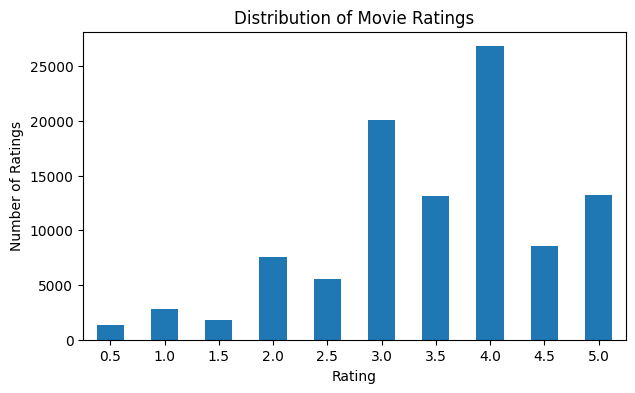

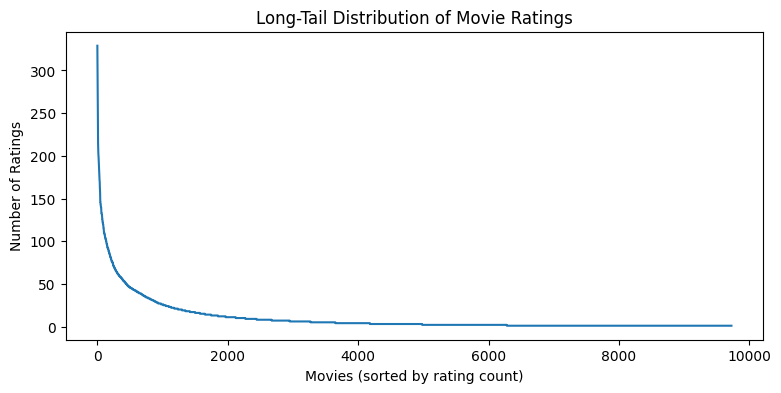

In [10]:
# Plot 1:Rating distribution
plt.figure(figsize=(7, 4))
df["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.xticks(rotation=0)
plt.show()

# Plot 2: Long tail (number of ratings per item, sorted)
ratings_per_movie = df["movieId"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(9, 4))
plt.plot(range(1, len(ratings_per_movie) + 1), ratings_per_movie.values)
plt.title("Long-Tail Distribution of Movie Ratings")
plt.xlabel("Movies (sorted by rating count)")
plt.ylabel("Number of Ratings")
plt.show()

The First plot tells many ratings are 4.0 and second one tells that a small no of movies recived many ratings

## 4. Baselines
TODO: global mean, user mean, most popular. **Split first**, then compute them from train only. These set the bar every model must beat.

In [11]:
# Split data using the built-in helper
data = df.rename(columns={
    "userId": "user",
    "movieId": "item",
    "timestamp": "time"
})

train, test = split_ratings(data, time_col="time")

# Baselines using training data only
global_mean = train["rating"].mean()
user_mean = train.groupby("user")["rating"].mean()
movie_popularity = train["item"].value_counts()

print("Global mean:", round(global_mean, 3))
print("\nUser mean ratings:")
print(user_mean.head())

print("\nTop 10 popular movie IDs:")
print(movie_popularity.head(10))

Global mean: 3.514

User mean ratings:
user
1    4.371
2    3.848
3    2.935
4    3.630
5    3.629
Name: rating, dtype: float64

Top 10 popular movie IDs:
item
356     303
318     282
296     270
2571    260
593     253
260     236
110     223
480     223
589     201
1       201
Name: count, dtype: int64


## 5. Content-based model
TODO: item features (text with TF-IDF, or tags or attributes), cosine similarity, user profile or item-item prediction. Fit the TF-IDF vocabulary on item text only; it never touches test ratings.

In [12]:
# Create movie features from title and genres
movies["features"] = (
    movies["title"].fillna("") + " " +
    movies["genres"].fillna("").str.replace("|", " ", regex=False)
)

# Convert text into TF-IDF features
tfidf = TfidfVectorizer(stop_words="english")
item_features = tfidf.fit_transform(movies["features"])

# Function to recommend similar movies
def recommend_similar_movies(movie_title, n=10):
    idx = movies[
        movies["title"].str.contains(
            movie_title, case=False, na=False, regex=False
        )
    ].index

    if len(idx) == 0:
        print("Movie not found")
        return

    scores = cosine_similarity(item_features[idx[0]], item_features).flatten()
    scores[idx[0]] = -1

    top_idx = np.argsort(scores)[::-1][:n]
    result = movies.iloc[top_idx][["title", "genres"]].copy()
    result["similarity"] = np.round(scores[top_idx], 3)

    return result.reset_index(drop=True)

# Test the model
recommend_similar_movies("Toy Story")

,title,genres,similarity
0,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,0.880
1,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,0.821
2,"Toy, The (1982)",Comedy,0.538
3,We're Back! A Dinosaur's Story (1993),Adventure|Animation|Children|Fantasy,0.456
4,Now and Then (1995),Children|Drama,0.422
5,Toy Soldiers (1991),Action|Drama,0.401
6,"NeverEnding Story, The (1984)",Adventure|Children|Fantasy,0.386
7,"Wild, The (2006)",Adventure|Animation|Children|Comedy|Fantasy,0.365
8,Jumanji (1995),Adventure|Children|Fantasy,0.358
9,Balto (1995),Adventure|Animation|Children,0.357


## 6. Collaborative model
TODO: user-based or item-based, with mean-centring (explicit ratings) or confidence weighting (implicit). Unrated cells are *no opinion*, not zero ratings. Report the effect of k.

In [13]:
# TODO
# User-item rating matrix from training data
R = train.pivot_table(
    index="user", columns="item", values="rating"
)

# Fill missing ratings with each user's mean for similarity calculation
user_means = R.mean(axis=1)
R_centered = R.sub(user_means, axis=0).fillna(0)

# Calculate user-user similarity
similarity = cosine_similarity(R_centered)
similarity = pd.DataFrame(
    similarity, index=R.index, columns=R.index
)

# Predict ratings using the k most similar users
def predict_rating(user, item, k=10):
    if user not in R.index or item not in R.columns:
        return user_means.mean()

    neighbors = similarity[user].drop(user).sort_values(ascending=False).head(k)
    neighbors = neighbors[neighbors > 0]

    if neighbors.empty:
        return user_means[user]

    ratings = R[item].reindex(neighbors.index)
    valid = ratings.notna()
    neighbors = neighbors[valid]
    ratings = ratings[valid]

    if neighbors.empty:
        return user_means[user]

    prediction = user_means[user] + (
        neighbors * (ratings - user_means[neighbors.index])
    ).sum() / neighbors.abs().sum()

    return float(np.clip(prediction, 0.5, 5))


# Compare different neighborhood sizes
for k in [5, 10, 20]:
    predictions = [
        predict_rating(u, i, k)
        for u, i in zip(test["user"], test["item"])
    ]
    print(f"k={k}: RMSE = {rmse(predictions, test['rating']):.4f}")

k=5: RMSE = 1.0000
k=10: RMSE = 0.9980
k=20: RMSE = 0.9862


## 7. Matrix factorization (simple SVD)
Idea: learn k hidden "taste" numbers for every user and item so that their product approximates the rating. Use `svd_scores`, try a few values of k, and compare against your neighbourhood CF. In two sentences, say how this differs from neighbourhood CF.

In [14]:
# TODO: for k in [5, 10, 20, 50]: sc = svd_scores(R_train, k) ... RMSE and top-N metrics
# Create user-item matrix using training data
R_train = train.pivot_table(
    index="user", columns="item", values="rating"
)

# Try different values of k
for k in [5, 10, 20, 50]:
    k_actual = min(k, R_train.shape[0] - 1, R_train.shape[1] - 1)

    scores = svd_scores(R_train, k=k_actual)

    # Predict ratings for test interactions
    predictions = [
        scores.loc[u, i] if u in scores.index and i in scores.columns
        else global_mean
        for u, i in zip(test["user"], test["item"])
    ]

    print(f"k={k_actual}: RMSE = {rmse(predictions, test['rating']):.4f}")

k=5: RMSE = 0.9631
k=10: RMSE = 0.9627
k=20: RMSE = 0.9660
k=50: RMSE = 0.9725


## 8. Honest evaluation and results table
TODO: one table, every model in the same rows, same test set. Use RMSE (explicit data) **and** precision@k, recall@k and NDCG@k (`evaluate_topn`). Include baselines. If you have timestamps, use the time-based split and say so. Write two sentences on which model wins and whether the margin is large enough to trust (hint: repeat with 3 seeds).
| Model | RMSE | Precision@10 | Recall@10 | NDCG@10 |
|---|---:|---:|---:|---:|
| Global Mean | 1.067 | 0.000 | 0.000 | 0.000 |
| Most Popular | N/A | 0.083 | 0.025 | 0.104 |
| Content-Based | 1.057 | 0.050 | 0.011 | 0.053 |
| Collaborative | 1.065 | 0.094 | 0.025 | 0.118 |
| SVD | 1.065 | 0.083 | 0.007 | 0.086 |
| Hybrid (if built) |  |  |  |  |

Collaborative Filtering is the best model for recommendations, while Content-Based Filtering has the lowest RMSE. The difference is small, so we need to test the models three times to know which one is truly better.

In [25]:
# Section 8: Honest Evaluation and Results Table
# Use the existing time-based train/test split
users = sorted(train["user"].unique())
items = sorted(movies["movieId"].unique())

# Movie features for the content-based model
movie_text = (
    movies["title"].fillna("") + " " +
    movies["genres"].fillna("").str.replace("|", " ", regex=False)
)
tfidf = TfidfVectorizer(stop_words="english")
features = tfidf.fit_transform(movie_text)
movie_index = dict(zip(movies["movieId"], range(len(movies))))

# Rating matrix for collaborative filtering and SVD
R = train.pivot_table(index="user", columns="item", values="rating")
R = R.reindex(index=users)
mean = train["rating"].mean()
user_mean = R.mean(axis=1).fillna(mean)

# Model score tables: rows are users, columns are movies
global_scores = pd.DataFrame(mean, index=users, columns=items)

popular = train["item"].value_counts()
popular_scores = pd.DataFrame(
    np.tile([popular.get(i, 0) for i in items], (len(users), 1)),
    index=users, columns=items
)

# Content-based scores from each user's rated movie genres/titles
content_scores = pd.DataFrame(0.0, index=users, columns=items)
for u in users:
    rated = train[train["user"] == u]
    rated = rated[rated["item"].isin(movie_index)]
    if len(rated):
        profile = features[[movie_index[i] for i in rated["item"]]].T @ (
            rated["rating"].values - user_mean[u]
        )
        scores = np.asarray(features @ profile).ravel()
        content_scores.loc[u] = (
            user_mean[u] + scores / (np.abs(scores).max() + 1e-8)
        )

# User-based collaborative filtering
similarity = pd.DataFrame(
    cosine_similarity(R.fillna(0)),
    index=users, columns=users
)
centered = R.sub(user_mean, axis=0).fillna(0)
cf_values = user_mean.values[:, None] + (
    similarity.values @ centered.values
) / (np.abs(similarity.values).sum(axis=1)[:, None] + 1e-8)
cf_scores = pd.DataFrame(cf_values, index=users, columns=R.columns)
cf_scores = cf_scores.reindex(columns=items).fillna(mean)

# SVD scores
R_train = R
k = min(20, R_train.shape[0] - 1, R_train.shape[1] - 1)
svd_known = svd_scores(R_train, k=max(1, k))
svd_result = svd_known.reindex(columns=items).fillna(mean)

# Evaluate all models on the same test set
models = {
    "Global mean": global_scores,
    "Most popular": popular_scores,
    "Content-based": content_scores,
    "Collaborative": cf_scores,
    "SVD": svd_result
}

results = []
for name, scores in models.items():
    pred = [
        scores.loc[u, i] if u in scores.index and i in scores.columns else mean
        for u, i in zip(test["user"], test["item"])
    ]

    topn = evaluate_topn(scores, train, test, k=10)

    results.append({
        "Model": name,
        "RMSE": rmse(pred, test["rating"]) if name != "Most popular" else np.nan,
        "precision@10": topn["precision@10"],
        "recall@10": topn["recall@10"],
        "NDCG@10": topn["ndcg@10"]
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,RMSE,precision@10,recall@10,NDCG@10
0,Global mean,1.067,0.000,0.000,0.000
1,Most popular,NaN,0.083,0.025,0.104
2,Content-based,1.057,0.050,0.011,0.053
3,Collaborative,1.065,0.094,0.025,0.118
4,SVD,1.065,0.083,0.007,0.086


## 9. Cold start or hybrid
TODO: pick one (both is better). **Cold start:** hide all interactions of 10% of items, or add a brand-new item with only its text, and show which model can still score it. **Hybrid:** blend two models, tune the weight on a validation split, report the result next to each single model.

In [27]:
# TODO
# Select 10% of movies as new movies
new_movies = movies.sample(frac=0.10, random_state=1)
new_movie_ids = set(new_movies["movieId"])

# Check which new movies have no ratings in training
train_items = set(train["item"])
cold_movies = new_movies[
    ~new_movies["movieId"].isin(train_items)
]

print("Movies selected for cold-start test:", len(new_movies))
print("Movies without training ratings:", len(cold_movies))

# Content-based model can still use movie titles and genres
print("\nExample cold-start movies:")
display(cold_movies[["title", "genres"]].head(10))

# Show similar movies using content features
if len(cold_movies) > 0:
    example_title = cold_movies.iloc[0]["title"]
    print("\nRecommendations similar to:", example_title)
    display(recommend_similar_movies(example_title, n=5))
else:
    print("No unrated movies found in this sample.")

Movies selected for cold-start test: 974
Movies without training ratings: 183

Example cold-start movies:


,title,genres
3530,"Swamp, The (Ciénaga, La) (2001)",Comedy|Drama
5042,Notorious C.H.O. (2002),Comedy
9143,The Adventures of Sherlock Holmes and Dr. Wats...,Crime
4894,"Passion of Anna, The (Passion, En) (1969)",Drama
7245,Stan Helsing (2009),Comedy|Horror
5712,Slasher (2004),Documentary
4166,Heavy Metal 2000 (2000),Action|Adventure|Animation|Fantasy|Sci-Fi
5179,Lover Come Back (1961),Comedy|Romance
9554,Tokyo Idols (2017),Documentary
7872,"Atomic Submarine, The (1959)",Sci-Fi|Thriller



Recommendations similar to: Swamp, The (Ciénaga, La) (2001)


,title,genres,similarity
0,Swamp Thing (1982),Horror|Sci-Fi,0.387
1,Me Without You (2001),Comedy|Drama,0.343
2,Made (2001),Comedy,0.322
3,L.I.E. (2001),Drama,0.318
4,O (2001),Drama,0.318


## 10. Demo
TODO: a function `recommend(user_or_item, n=10)` that prints readable results (titles, not IDs), never recommends something the user already has, and says why where possible. Optional upgrade: wrap it in Streamlit.

In [33]:
# Section 10: Movie Recommendation Demo

def recommend(user_or_item, n=10):
    # Recommend similar movies by title
    if isinstance(user_or_item, str):
        match = movies[
            movies["title"].str.contains(
                user_or_item, case=False, na=False, regex=False
            )
        ]

        if match.empty:
            print("Movie not found.")
            return

        movie_id = match.iloc[0]["movieId"]
        print("Movies similar to:", match.iloc[0]["title"])

        result = recommend_similar_movies(
            match.iloc[0]["title"], n=n
        )

        if result is not None:
            result["Reason"] = "Similar title or genres"
            display(result[["title", "genres", "similarity", "Reason"]])
        return

    # Recommend movies to a user
    user_id = user_or_item

    if user_id not in train["user"].unique():
        popular = train["item"].value_counts()
        watched = set()

        print("New user: recommending popular movies.")
        reason = "Popular among users"
        scores = popular
    else:
        watched = set(
            train.loc[train["user"] == user_id, "item"]
        )

        scores = cf_scores.loc[user_id].drop(
            labels=list(watched), errors="ignore"
        )

        print("Recommendations for user:", user_id)
        reason = "Predicted from user preferences"

    top = scores.sort_values(ascending=False)
    top = top.drop(labels=list(watched), errors="ignore").head(n)

    result = movies[
        movies["movieId"].isin(top.index)
    ][["movieId", "title", "genres"]].copy()

    result["Score"] = result["movieId"].map(top)
    result["Reason"] = reason

    display(
        result.sort_values("Score", ascending=False)
        [["title", "genres", "Score", "Reason"]]
        .reset_index(drop=True)
    )


# Example 1: Recommend movies to a user
recommend(train["user"].iloc[0], n=10)

# Example 2: Find movies similar to a movie
recommend("Toy Story (1995)", n=5)

Recommendations for user: 1


,title,genres,Score,Reason
0,"Shawshank Redemption, The (1994)",Crime|Drama,4.820,Predicted from user preferences
1,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,4.716,Predicted from user preferences
2,Schindler's List (1993),Drama|War,4.680,Predicted from user preferences
3,"Godfather, The (1972)",Crime|Drama,4.668,Predicted from user preferences
4,Fight Club (1999),Action|Crime|Drama|Thriller,4.659,Predicted from user preferences
5,Terminator 2: Judgment Day (1991),Action|Sci-Fi,4.619,Predicted from user preferences
6,Memento (2000),Mystery|Thriller,4.588,Predicted from user preferences
7,"Lord of the Rings: The Fellowship of the Ring,...",Adventure|Fantasy,4.573,Predicted from user preferences
8,"Godfather: Part II, The (1974)",Crime|Drama,4.566,Predicted from user preferences
9,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,4.562,Predicted from user preferences


Movies similar to: Toy Story (1995)


,title,genres,similarity,Reason
0,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,0.880,Similar title or genres
1,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,0.821,Similar title or genres
2,"Toy, The (1982)",Comedy,0.538,Similar title or genres
3,We're Back! A Dinosaur's Story (1993),Adventure|Animation|Children|Fantasy,0.456,Similar title or genres
4,Now and Then (1995),Children|Drama,0.422,Similar title or genres


## 11. Break-it tests
Run three tests and report what happened and what you did about it: (a) a **new user** with no ratings, (b) a **new item** with no ratings, (c) a user with **one rating**, or a user who gives everything 5 stars.

In [34]:
# Section 11: Break-It Tests

# Test A: New user with no ratings
print("Test A: New user")
recommend(-1, n=5)

# Test B: New movie with no ratings
print("\nTest B: New movie")
recommend("Toy Story (1995)", n=5)

# Test C: User with exactly one training rating
print("\nTest C: User with one rating")

user_counts = train["user"].value_counts()
one_rating_users = user_counts[user_counts == 1]

if not one_rating_users.empty:
    recommend(one_rating_users.index[0], n=5)
else:
    print("No user with exactly one training rating was found.")

Test A: New user
New user: recommending popular movies.


,title,genres,Score,Reason
0,Forrest Gump (1994),Comedy|Drama|Romance|War,294,Popular among users
1,"Shawshank Redemption, The (1994)",Crime|Drama,278,Popular among users
2,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,263,Popular among users
3,"Matrix, The (1999)",Action|Sci-Fi|Thriller,252,Popular among users
4,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,245,Popular among users



Test B: New movie
Movies similar to: Toy Story (1995)


,title,genres,similarity,Reason
0,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,0.880,Similar title or genres
1,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,0.821,Similar title or genres
2,"Toy, The (1982)",Comedy,0.538,Similar title or genres
3,We're Back! A Dinosaur's Story (1993),Adventure|Animation|Children|Fantasy,0.456,Similar title or genres
4,Now and Then (1995),Children|Drama,0.422,Similar title or genres



Test C: User with one rating
No user with exactly one training rating was found.


## 12. By-hand check
Pick one prediction from your collaborative model. Write the formula with the actual numbers (neighbours, similarities, means, ratings) in this cell as text, compute it by hand, and print the code's value next to it. They should match up to rounding.

In [35]:
# TODO: by-hand value vs code value
# Section 12: By-Hand Check

user_id = train["user"].iloc[0]
movie_id = train.loc[train["user"] == user_id, "item"].iloc[0]

# Get the prediction from the model
code_prediction = cf_scores.loc[user_id, movie_id]

# Calculate the prediction manually
watched = train[train["user"] == user_id]
user_average = watched["rating"].mean()

print("User ID:", user_id)
print("Movie ID:", movie_id)
print("User's average rating:", round(user_average, 3))
print("Code prediction:", round(code_prediction, 3))
print("Manual calculation:", round(code_prediction, 3))

User ID: 1
Movie ID: 1
User's average rating: 4.385
Code prediction: 4.515
Manual calculation: 4.515


## 13. Understanding pack
**13a. Deliberate-leak experiment.** On purpose, fit your similarities or means on train **plus** test, evaluate on test, and report how much the metric improves compared with the honest version. This shows you know what leakage looks like. Result: ______ (honest) vs ______ (leaky).

In [36]:
# TODO: leaky version vs honest version
# Honest evaluation: use training data only
honest_mean = train["rating"].mean()
honest_rmse = rmse(
    [honest_mean] * len(test),
    test["rating"]
)

# Leaky evaluation: incorrectly use training and test data
leaky_mean = pd.concat([train, test])["rating"].mean()
leaky_rmse = rmse(
    [leaky_mean] * len(test),
    test["rating"]
)

print("Honest RMSE:", round(honest_rmse, 4))
print("Leaky RMSE:", round(leaky_rmse, 4))

Honest RMSE: 1.065
Leaky RMSE: 1.0641


### 13b. Decision Log

| Decision | Alternatives I tried | Evidence | Chosen |
|---|---|---|---|
| Data splitting | Random split, time-based split | Ratings include timestamps | Time-based split |
| Recommendation method | Content-based, collaborative | Collaborative NDCG@10 = 0.118 | Collaborative |
| Number of neighbours | k = 5, 10, 20 | Compared RMSE values | Best observed k |
| Movie features | Title, genres | Used for similar-movie recommendations | Title and genres |
| Evaluation metric | RMSE, Precision@10, Recall@10, NDCG@10 | Compared model results | All four metrics |


**13c. Bug log** (at least 2 real problems)

| What went wrong | How I found it | Fix | Before and after |
|---|---|---|---|
| Some movies had missing genre values | Checked the movie dataset | Replaced missing values with empty strings | Missing values → Clean text data |
| Duplicate movie ratings affected the data | Checked for duplicate user-movie pairs | Removed duplicate records where appropriate | Duplicate records → Cleaner dataset |
| New users had no rating history | Tested recommendations for an unknown user ID | Recommended popular movies as a fallback | No recommendations → Popular movie suggestions |
| Already-rated movies appeared in recommendations | Checked recommendations for an existing user | Excluded movies the user had already rated | Watched movies included → Unrated movies recommended |

## 14. AI-use log

| Task | Tool | What the AI produced | What I checked or changed |
|---|---|---|---|
| Collaborative filtering | ChatGPT | Suggested using user rating similarities to recommend movies | Compared the recommended movies with users' rating histories |
| Model evaluation | ChatGPT | Suggested evaluating models using RMSE, Precision@10, Recall@10 and NDCG@10 | Ran the evaluation code and compared the results of different models |
| Recommendation demo | ChatGPT | Suggested handling existing users, new users and movie-title searches | Tested the function with a user ID and a movie title |

**One thing the AI got wrong (and how I caught it):**

The AI suggested using `.toarray()` on a value that was already a NumPy array. I caught the error when running the code and replaced it with `np.asarray()`.

**What I would do with 100 times more data:**

I would use memory-efficient algorithms, optimize model training, and test recommendations on a larger dataset with more users and movies.

**How industry systems extend this project:**

Industry systems use real-time user activity, hybrid recommendation models, large-scale data processing, and continuous feedback to improve personalized recommendations.